# 21.6 Self-Attention 🔄

Self-attention is the case where **the same sequence produces the Query, Key, and Value representations**.

## 1. The Core Idea

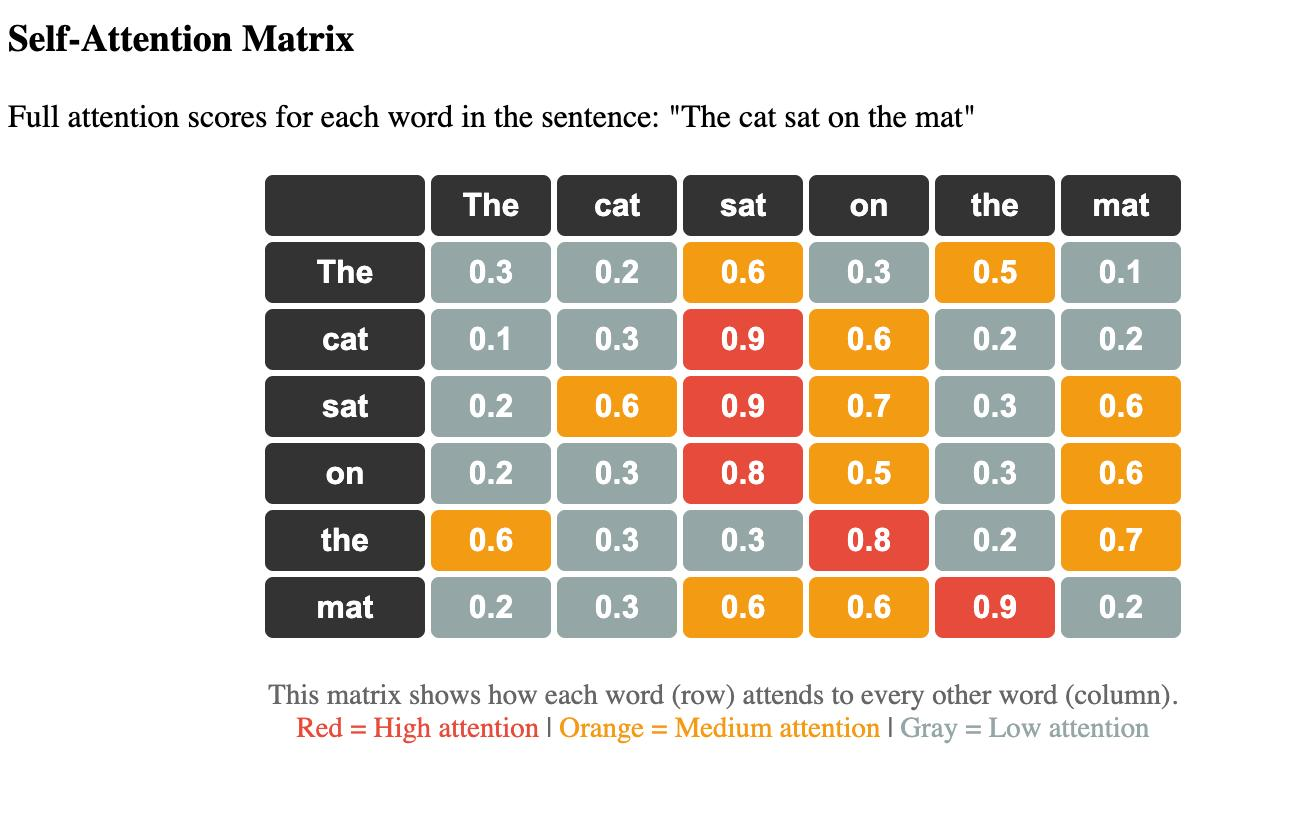

Suppose our sentence is:

> **"The cat eats fish."**

We start with token representations:

$$
X=[x_1,x_2,x_3,x_4]
$$

The **same \(X\)** is projected three different ways:

$$
\boxed{Q=XW_Q}
$$

$$
\boxed{K=XW_K}
$$

$$
\boxed{V=XW_V}
$$

So:

```text id="m9m7k2"
                 Same sequence X
                       │
                 ┌──────────┼──────────┐
                 ▼          ▼          ▼
                 Q          K          V
                 │          │          │
                 └─────┬────┘          │
                       ▼               │
                     QKᵀ               │
                       │               │
                       ▼               │
                   Softmax             │
                       │               │
                       └───────┬───────┘
                               ▼
                           Attention
                             Output
```

### Key point

The **same sequence** is the source of all three:

$$
\boxed{X\rightarrow Q,K,V}
$$

But \(Q,K,V\) have **different learned projections and different roles**.

---

# 2. Why Three Different Representations?

This is an important subtlety.

It does **not** mean:

> Every token has three completely unrelated meanings.

Instead, the model takes each token representation and creates three views of it:

### Query

$$
Q=XW_Q
$$

> **What information does this token need from other tokens?**

### Key

$$
K=XW_K
$$

> **What kind of information does this token offer for matching?**

### Value

$$
V=XW_V
$$

> **What information should this token provide if attended to?**

Therefore:

$$
\boxed{\text{Same token representation} \rightarrow \text{three learned roles}}
$$

---

# 3. Token-to-Token Relationships 🎯

This is the most important intuition behind **self-attention**.

In a normal sequence representation, each token starts with its own information.

Self-attention allows every token to examine the other tokens.

For:

> **"The cat eats fish."**

conceptually:

```text id="j7p1uk"
The  ─────► cat
 │          │
 │          ├────► eats
 │          │       │
 ▼          ▼       ▼
fish ◄──────┴───────┘
```

More precisely, every token can potentially attend to every other token:

```text id="0u8c9k"
             The   cat   eats  fish
The           ●     ●     ●     ●
cat           ●     ●     ●     ●
eats          ●     ●     ●     ●
fish          ●     ●     ●     ●
```

This produces a:

$$
\boxed{T\times T}
$$

attention matrix for a sequence of length \(T\).

Each row corresponds to a Query token.

Each column corresponds to a Key token.

---

# 4. What Does "Self" Mean?

The word **self** does not mean:

> “A token only attends to itself.”

❌ That's incorrect.

It means:

> **The Queries, Keys, and Values all originate from the same sequence.**

So token \(x_i\)'s Query can compare against the Keys of:

$$
x_1,x_2,\ldots,x_T
$$

including potentially its own Key.

Therefore:

$$
\boxed{
Q,K,V\leftarrow\text{same sequence}
}
$$

---

# 5. Example: Understanding a Word Using Context 🧠

Consider:

> **"The bank approved the loan."**

The word **bank** has an initial representation.

Through self-attention, its Query can attend to other tokens:

```text id="6o1s6n"
The   bank   approved   the   loan
      ↑         ↑              ↑
      └─────────┼──────────────┘
                │
           contextual clues
```

The tokens **approved** and **loan** provide contextual information that helps the representation of **bank** become more appropriate to this sentence.

This is one of the fundamental reasons self-attention is powerful for NLP:

$$
\boxed{
\text{Token representation}
+
\text{context from other tokens}
=
\text{contextual representation}
}
$$

The model does not need to treat each word as an isolated symbol.

---

# 6. Another Example: Long-Range Relationships

Consider:

> **"The animal didn't cross the road because it was tired."**

The representation of **"it"** can attend to other tokens, including earlier tokens that help establish what **"it"** refers to.

Conceptually:

```text id="n3f9rx"
The animal didn't cross the road because it was tired
    ↑                                      ↑
    └──────────────────────────────────────┘
                 relationship
```

The strength of this relationship is learned through attention scores.

This is what we mean by:

$$
\boxed{\text{token-to-token relationships}}
$$

---

# 7. The Mathematical Flow

For self-attention:

### Step 1 — Input

$$
X
$$

### Step 2 — Create Q/K/V

$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

### Step 3 — Calculate relationships

$$
QK^T
$$

### Step 4 — Scale

$$
\frac{QK^T}{\sqrt{d_k}}
$$

### Step 5 — Normalize

$$
A=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)
$$

### Step 6 — Aggregate information

$$
\boxed{
O=AV
}
$$

Therefore:

$$
\boxed{
O=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
}
$$

Exactly the same scaled dot-product attention equation you just learned.

---

# 8. What Does Each Row Mean?

This is extremely useful when visualizing attention.

Suppose:

```text id="r4q9v7"
             The   cat   eats   fish
The          0.4   0.3   0.2    0.1
cat          0.1   0.5   0.3    0.1
eats         0.1   0.3   0.4    0.2
fish         0.1   0.2   0.5    0.2
```

The **row for "cat"** tells us:

> When processing **cat**, how much attention is paid to each token?

So:

$$
\boxed{
\text{Row}_i
=
\text{attention distribution for Query }i
}
$$

And each row sums approximately to 1 because of softmax.

---

# 9. Self-Attention Creates Contextual Representations

Before attention:

```text id="g9zv9j"
cat → representation of "cat"
```

After self-attention:

```text id="t3qj5s"
cat
 │
 ├── information from "The"
 ├── information from "eats"
 └── information from "fish"
        ↓
 contextual representation of "cat"
```

So each output representation can incorporate information from the surrounding sequence.

This is a major conceptual transition from **static word representations** to **context-dependent representations**.

---

# 10. Self-Attention vs Your Earlier Seq2Seq Attention

This distinction is important because you're coming from classical Seq2Seq attention.

### Seq2Seq cross-attention

Typically:

$$
\boxed{
Q\leftarrow Decoder
}
$$

$$
\boxed{
K,V\leftarrow Encoder
}
$$

The decoder is looking **into another sequence**.

---

### Self-attention

$$
\boxed{
Q,K,V\leftarrow Same\ sequence
}
$$

The sequence is effectively looking **within itself**.

```text id="q9k1w8"
SELF-ATTENTION

       Same sequence
            │
       ┌─────┼─────┐
       ▼     ▼     ▼
       Q     K     V
        \    │    /
         \   │   /
          Attention
             │
             ▼
       contextual output
```

This distinction becomes fundamental when you study the **Transformer encoder and decoder**.

---

# 11. A Very Important Insight 🔥

Self-attention does **not** inherently mean:

> “Look only at nearby words.”

There is no built-in fixed window like:

```text
← 3 tokens | current | 3 tokens →
```

Instead, the attention mechanism can calculate relationships between positions across the sequence.

For example:

```text id="q8n2p6"
Token 1 ──────────────────────► Token 20
Token 20 ─────────────────────► Token 1
```

Whether a relationship receives high or low attention is determined by the learned representations and attention computation.

This is particularly useful for language because meaningful relationships can occur far apart.

---

# 12. But There's a Catch: Positional Information 📍

Self-attention by itself doesn't inherently encode the sequential order of tokens.

For example:

> **"dog bites man"**

and:

> **"man bites dog"**

contain the same tokens but have different meanings.

Therefore Transformers need **positional information** to distinguish token positions.

You already encountered positional embeddings/encoding in your DL syllabus, so we won't reteach that from scratch. Here, just remember:

$$
\boxed{
\text{Self-attention}
+
\text{positional information}
\rightarrow
\text{sequence-aware representations}
}
$$

We'll revisit this in the Transformer architecture modules.

---

# 13. Self-Attention in One Diagram

Think of the attention matrix as a **relationship map**:

```text id="f2q7ph"
                KEY
             The cat eats fish
           ┌──────────────────
QUERY  The │ ●   ●   ●   ●
       cat │ ●   ●   ●   ●
      eats │ ●   ●   ●   ●
      fish │ ●   ●   ●   ●
```

A strong cell means:

> **This Query token is strongly attending to this Key token.**

That is why attention visualizations are often displayed as heatmaps.

---

# 14. Industry / NLP Relevance 🚀

Self-attention is foundational to:

- **BERT** — encoder self-attention
- **GPT-style models** — decoder self-attention with causal masking
- **T5** — encoder and decoder self-attention plus cross-attention
- modern Transformer-based NLP systems

You don't need to memorize all those architectures yet. The important foundation is:

$$
\boxed{
\text{Self-attention}
\rightarrow
\text{Transformer}
\rightarrow
\text{modern NLP models}
}
$$

---

# 🎯 Self-Attention Cheat Sheet

| Question | Answer |
|---|---|
| What produces Q? | Input sequence \(X\) |
| What produces K? | Same input sequence \(X\) |
| What produces V? | Same input sequence \(X\) |
| Formula | \(Q=XW_Q,\ K=XW_K,\ V=XW_V\) |
| What does \(QK^T\) measure? | Token-to-token compatibility |
| What does softmax produce? | Attention weights |
| What do weights act on? | Values \(V\) |
| Output | Weighted combination of Values |
| Main purpose | Build contextual token representations |
| Why "self"? | Q/K/V originate from the same sequence |

---

## 🧠 The one mental model to keep

For every token:

> **My Query asks what context I need.**

> **Other tokens' Keys determine how relevant they are to my request.**

> **Their Values provide the information I actually receive.**

So:

$$
\boxed{
X
\rightarrow
(Q,K,V)
\rightarrow
QK^T
\rightarrow
\text{Softmax}
\rightarrow
\text{weighted }V
\rightarrow
\text{contextual representation}
}
$$

### What you should remember

1. **Self-attention uses the same sequence to produce \(Q,K,V\).**
2. Every token can potentially attend to every other token.
3. \(QK^T\) creates the **token-to-token relationship/compatibility matrix**.
4. Softmax converts those scores into attention weights.
5. The weights determine how Values are combined.
6. The result is a **contextual representation** for every token.
7. **Self-attention = attention within the same sequence.**
---